# MST project · Virtual winding-temperature sensor (one-file summary)

**UCS321 AI for Engineers · MST statement #6 (GE Power Systems scenario)**

**Goal:** Present the whole project in one notebook, in rubric order: problem → data → pre-processing → models → evaluation → innovation. Every number is **read from the results files** written by notebooks 01–06, and section 7 re-runs the final model on one test session end to end to show the pipeline really works.

**Inputs:** `outputs/results/*.json|csv`, `outputs/figures/*.png`, and for section 7 the saved model (`outputs/models/`) + `data/processed/measures_v2.parquet`.
**Outputs:** none (read-only summary).

The detailed work, with every step explained, is in `notebooks/01_data_check` … `06_innovation`, and the full reasoning is in `LOG.md`.

In [1]:
import json
import sys
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))
from src import config, features
from src.data import load_split
from src.modelling import regression_metrics

R = config.RESULTS_DIR
F = config.FIGURES_DIR
def load(name):
    return json.load(open(R / name))
check, eda, feats, modelling, evaluation, innovation = (load(n) for n in [
    "data_check_summary.json", "eda_summary.json", "features_summary.json",
    "modelling_summary.json", "evaluation_summary.json", "innovation_summary.json"])
split = load_split()

## 1. Problem (Phase 1)
The copper **stator winding** heats up with current (I²R loss). Its insulation ages much faster when hot (life roughly halves per +10 °C; Class F limit 155 °C). A sensor inside the winding is costly and fragile, so we estimate the temperature from signals the controller already has (ambient, coolant, u_d, u_q, i_d, i_q, speed, torque). That's a **virtual sensor**, built with **supervised regression**. The three neighbouring temperatures (`pm`, `stator_tooth`, `stator_yoke`) are forbidden inputs. Full write-up: `docs/problem.md`.

## 2. Data (Phase 0)

In [2]:
display(Markdown(f'''
| Fact | Value |
|---|---|
| Rows × columns | {check['n_rows']:,} × {check['n_columns']} |
| Sessions | {check['n_profiles']} (IDs {check['profile_id_min']}–{check['profile_id_max']}) |
| Hours | {check['total_hours']} |
| Missing / duplicate rows | {check['missing_values_total']} / {check['duplicate_rows']} |
| Winding range | {check['temperature_range_check'][2]['min_C']}–{check['temperature_range_check'][2]['max_C']} °C |
| Row order = time order | median row step {check['median_step_stator_winding_file_order_C']} °C vs {check['median_step_stator_winding_shuffled_C']} °C shuffled |
'''))


| Fact | Value |
|---|---|
| Rows × columns | 1,330,816 × 13 |
| Sessions | 69 (IDs 2–81) |
| Hours | 184.84 |
| Missing / duplicate rows | 0 / 0 |
| Winding range | 18.59–141.36 °C |
| Row order = time order | median row step 0.02208 °C vs 28.85482 °C shuffled |


## 3. Split and EDA (Phase 2)
The test sessions were frozen **before** any exploration, and all EDA used training sessions only.


- **Test sessions:** [6, 7, 21, 61, 66, 81] (10.60 % of rows); **training:** 63 sessions.
- **Leakage proof:** r with target: stator_tooth 0.97, stator_yoke 0.862, pm 0.796; best allowed input i_d -0.632.
- **Thermal lag:** median best lag 2.5 min; r 0.645 → 0.746 (53 sessions).


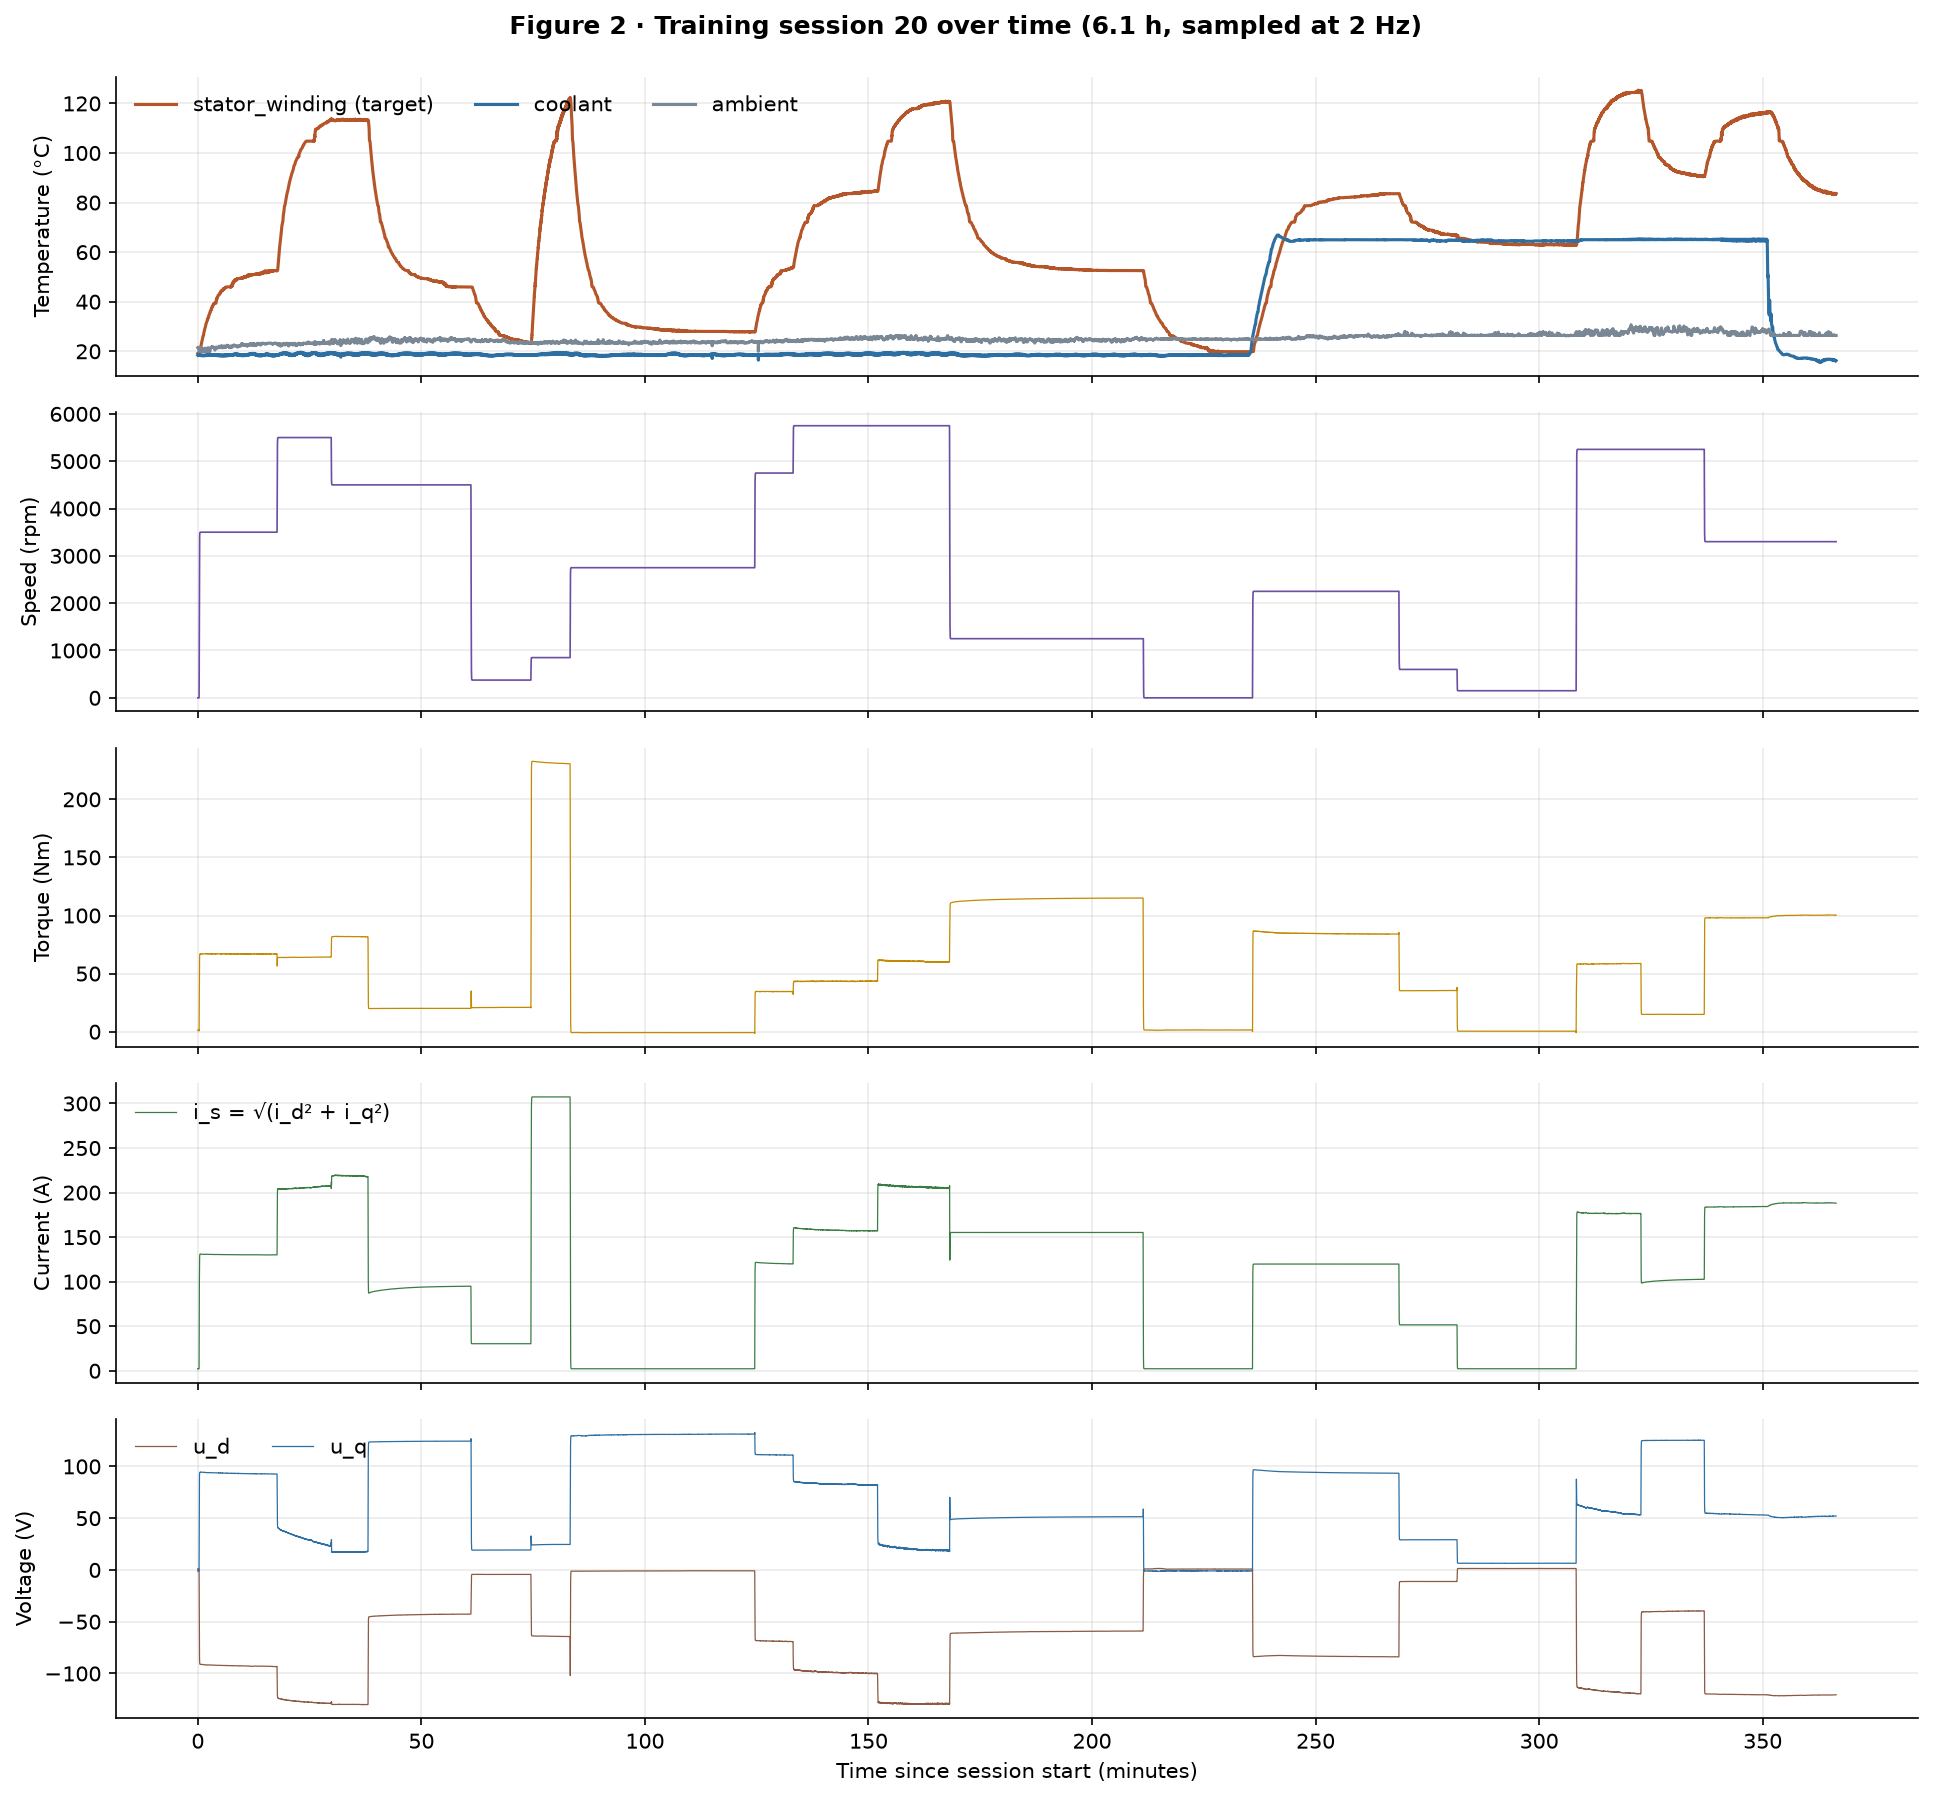

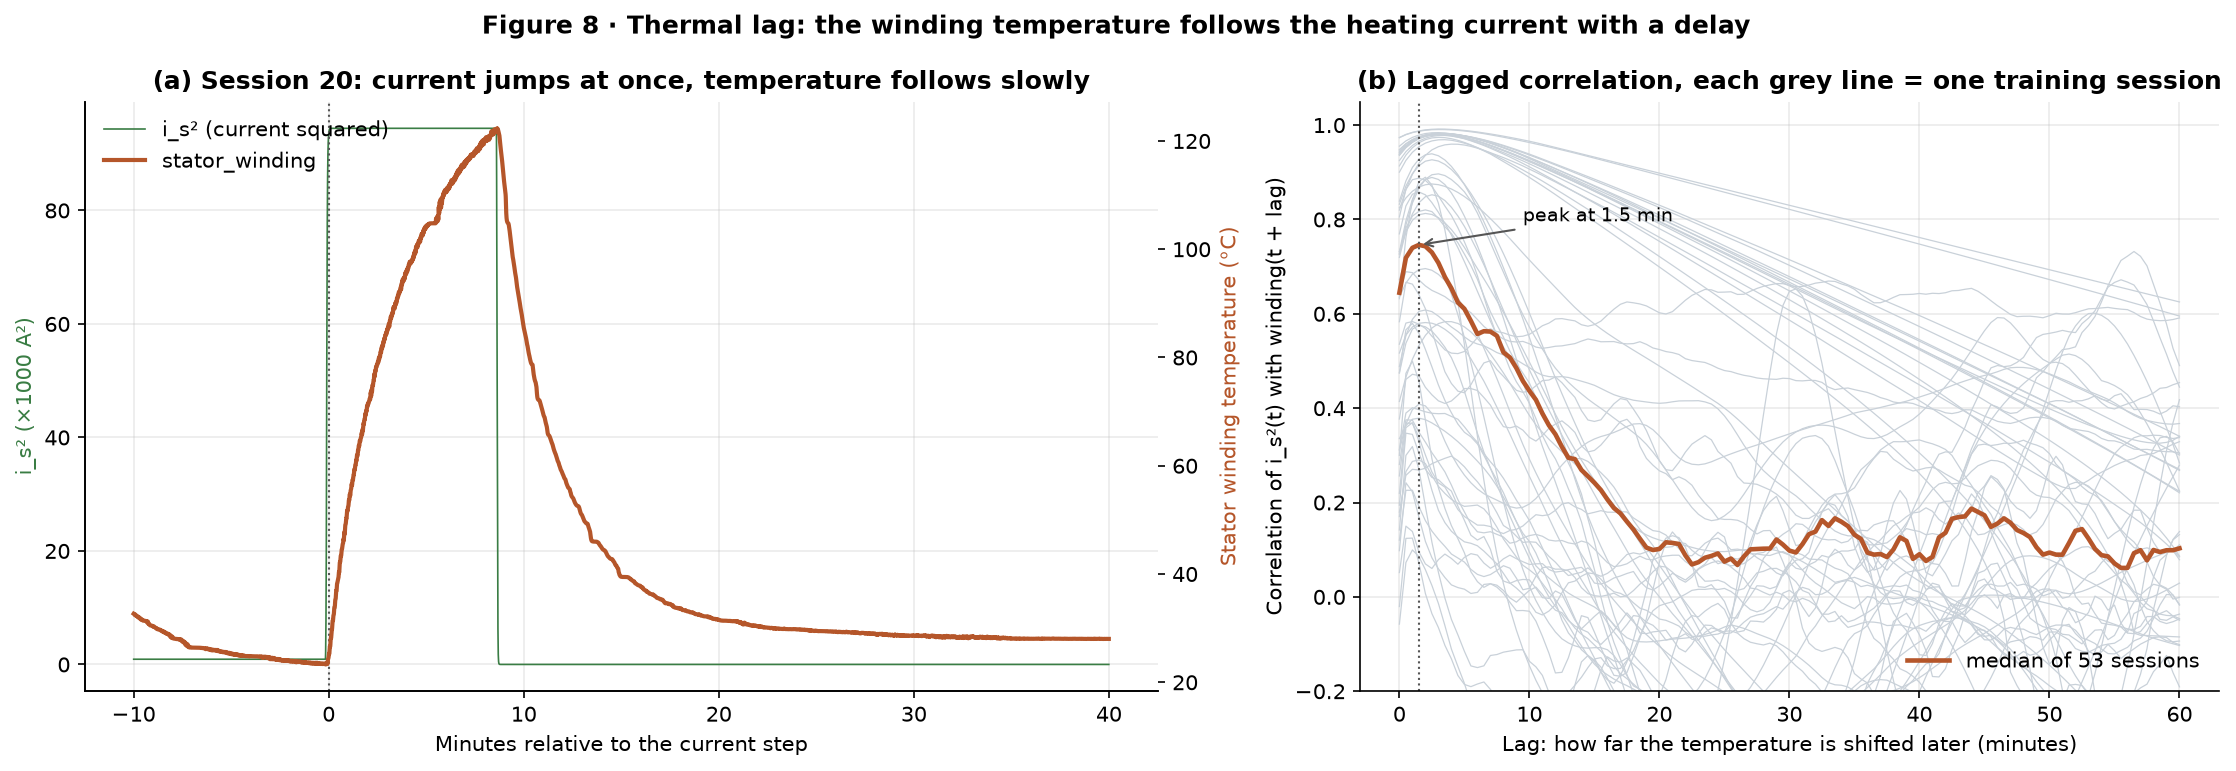

In [3]:
lag = eda["thermal_lag"]
display(Markdown(f'''
- **Test sessions:** {split['test_profiles']} ({100 * split['test_share_of_rows']:.2f} % of rows); **training:** {len(split['train_profiles'])} sessions.
- **Leakage proof:** r with target: stator_tooth {eda['corr_with_target']['stator_tooth']}, stator_yoke {eda['corr_with_target']['stator_yoke']}, pm {eda['corr_with_target']['pm']}; best allowed input i_d {eda['corr_with_target']['i_d']}.
- **Thermal lag:** median best lag {lag['median_best_lag_min']} min; r {lag['median_corr_at_lag0']} → {lag['median_best_corr']} ({lag['sessions_analysed']} sessions).
'''))
display(Image(filename=str(F / "eda_02_session20_over_time.png"), width=900))
display(Image(filename=str(F / "eda_08_thermal_lag.png"), width=900))

## 4. Flow diagram and features (Phase 3)

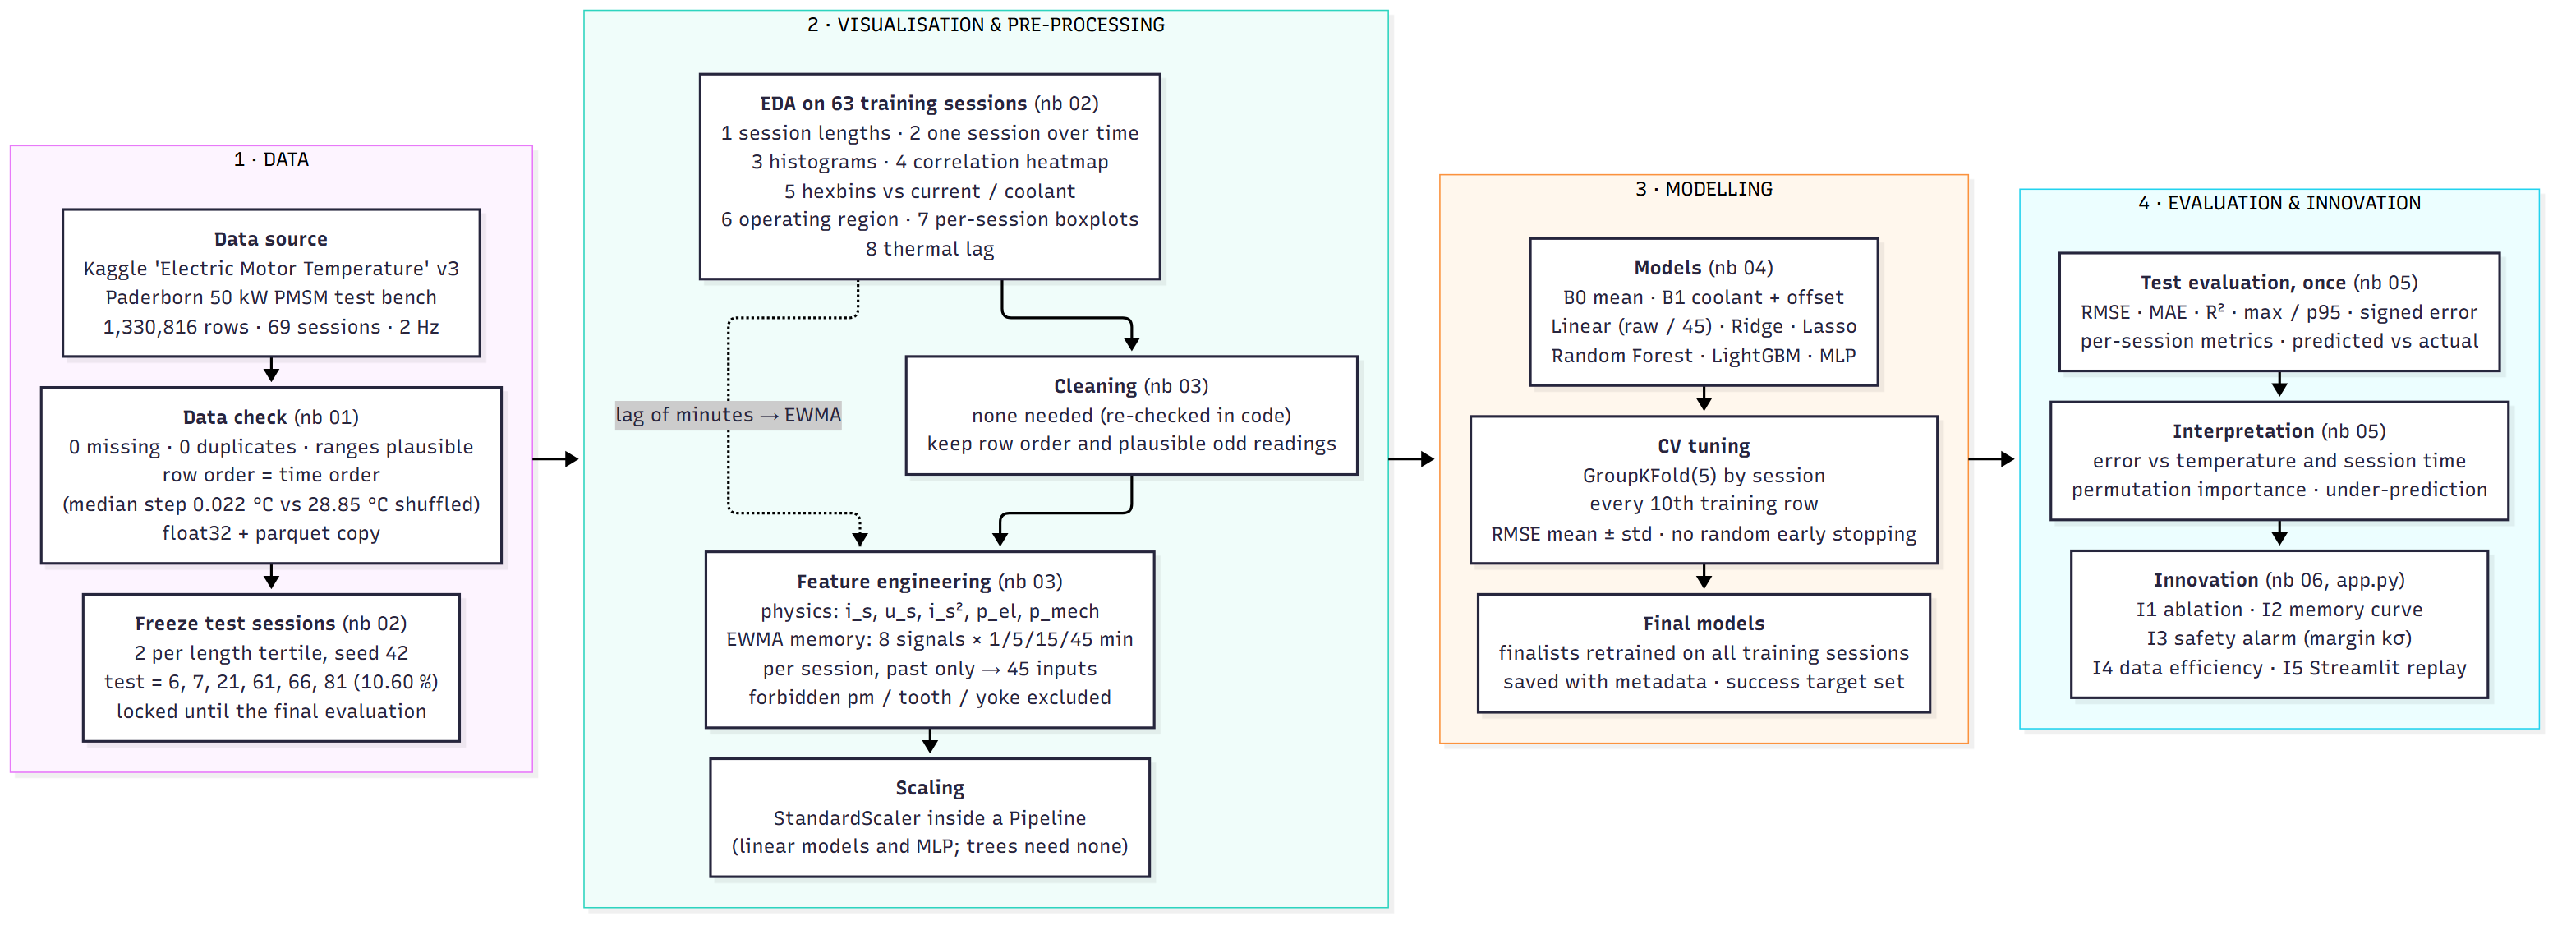

**45 inputs** = 8 raw + 5 physics + 32 EWMA (spans 1/5/15/45 min). EWMA causality check: max difference 0.0. Raw i_s r = 0.583 → best i_s EWMA r = 0.705.

In [4]:
display(Image(filename=str(config.PROJECT_DIR / "docs" / "flow_diagram.png"), width=1000))
display(Markdown(f"**{feats['n_features']} inputs** = 8 raw + 5 physics + 32 EWMA (spans 1/5/15/45 min). "
                 f"EWMA causality check: max difference {feats['causality_max_diff']}. "
                 f"Raw i_s r = {feats['i_s_raw_r']} → best i_s EWMA r = {feats['i_s_best_ewma_r']}."))

## 5. Models (Phase 4): GroupKFold(5) cross-validation on the training sessions

,model,rmse_mean,rmse_std,mae_mean,r2_mean,train_rmse_mean,fit_seconds_per_fold,n_features
0,M6 MLP (64-32),4.919,0.763,3.116,0.970,2.663,17.105,45
1,M5 LightGBM,5.061,0.836,3.317,0.968,1.144,5.811,45
2,M3 Ridge,5.172,0.576,3.052,0.966,4.992,0.302,45
3,M2 Linear (45 features),5.178,0.564,3.066,0.966,4.987,0.477,45
4,M3 Lasso,5.202,0.615,3.019,0.966,5.046,23.192,45
5,M4 Random Forest,5.822,0.844,3.788,0.958,2.327,10.342,45
6,M1 Linear (8 raw),16.093,1.600,12.241,0.681,15.554,0.071,8
7,B1 coolant + offset,26.033,1.636,20.397,0.159,25.944,0.017,8
8,B0 mean,29.088,1.258,24.244,-0.031,28.961,0.026,8


**Finalists:** ['M6 MLP (64-32)', 'M5 LightGBM', 'M3 Ridge']. **Success target (set before testing):** test RMSE ≤ 6.5 °C and ≤ 13.017 °C (half of B1).

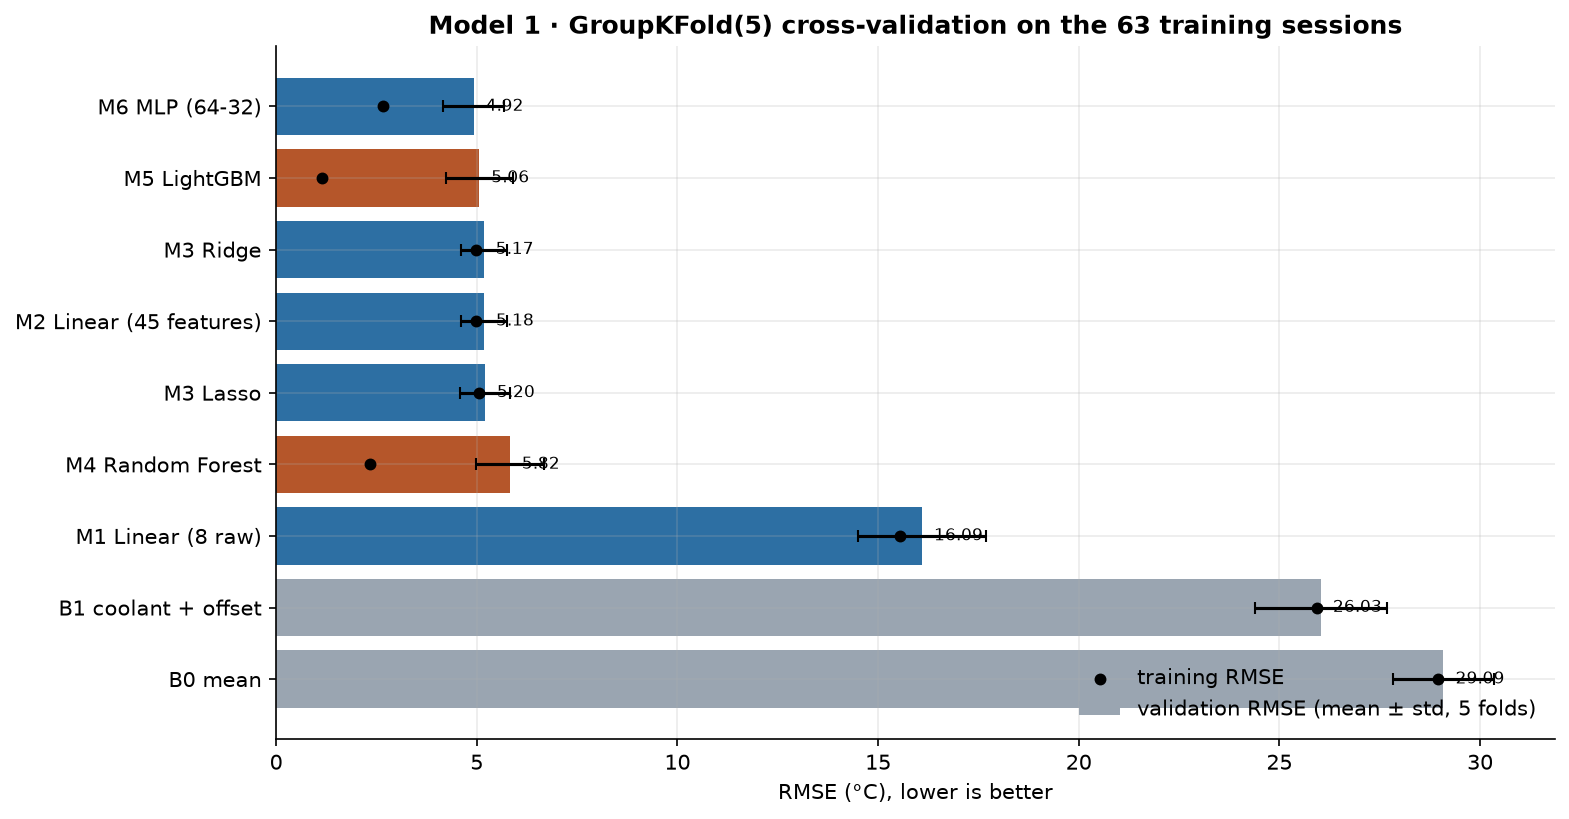

In [5]:
cv = pd.DataFrame(modelling["cv_table"])[["model", "rmse_mean", "rmse_std", "mae_mean", "r2_mean", "train_rmse_mean", "fit_seconds_per_fold", "n_features"]]
display(cv.round(3))
display(Markdown(f"**Finalists:** {modelling['finalists']}. **Success target (set before testing):** test RMSE ≤ {modelling['success_target']['test_rmse_max']} °C and ≤ {modelling['success_target']['test_rmse_max_vs_b1']} °C (half of B1)."))
display(Image(filename=str(F / "model_01_cv_comparison.png"), width=850))

## 6. Final test evaluation (Phase 5, test set used once)

,rmse,mae,r2,max_abs_error,p95_abs_error,mean_signed_error,session_mean_mae
model,,,,,,,
M3 Ridge,4.966,2.993,0.963,73.573,9.030,0.380,2.847
M5 LightGBM,5.105,2.860,0.961,74.873,9.877,-0.874,2.380
M6 MLP (64-32),6.005,3.693,0.946,60.312,14.597,-1.946,2.991
B1 coolant + offset,24.484,20.147,0.106,72.000,50.917,2.404,19.543
B0 mean,25.941,22.225,-0.004,63.495,45.961,-1.626,23.078


Test set opened at **2026-10-10 09:24:52**. Final model **M6 MLP (64-32)**. Targets met: target 1 **True**, target 2 **True**.

,profile_id,hours,rmse,mae,max_abs_error,mean_signed_error
2,6,5.609,9.430,7.635,21.873,-6.599
7,7,2.035,1.226,0.800,6.175,0.297
12,21,2.406,5.988,3.318,60.312,-1.252
17,61,2.016,3.620,2.371,22.669,-0.538
22,66,5.066,3.708,2.194,34.226,0.122
27,81,2.454,2.998,1.630,17.923,0.723


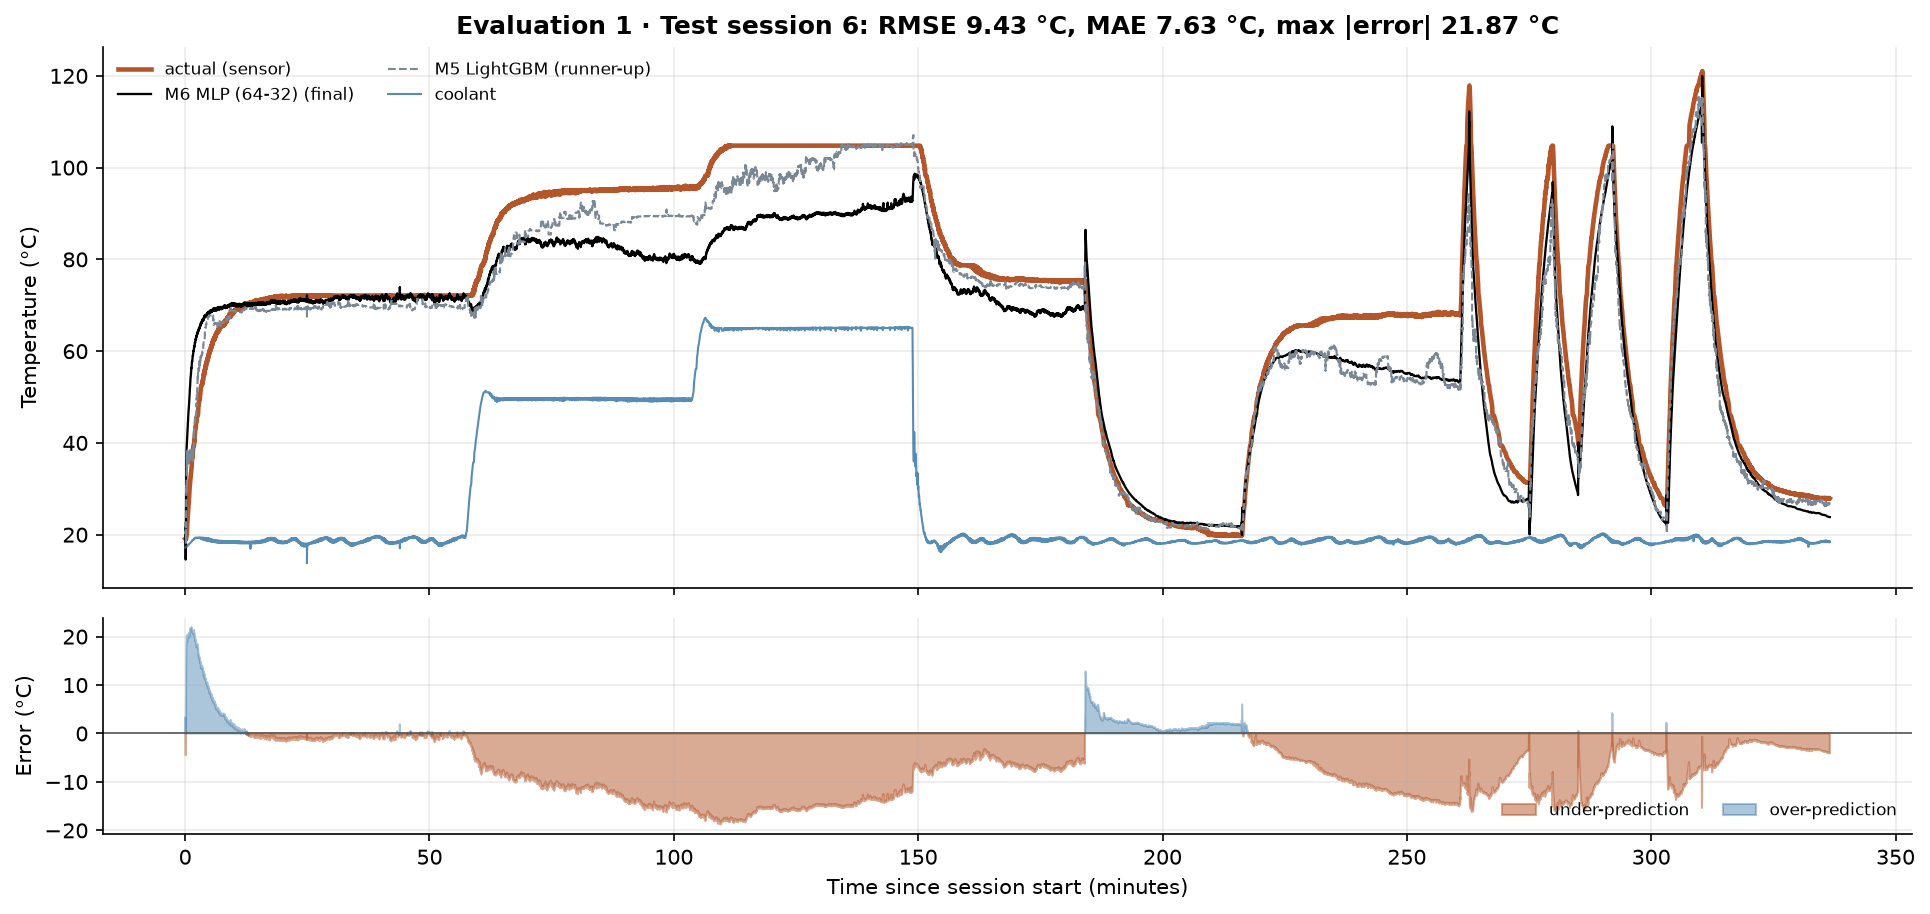

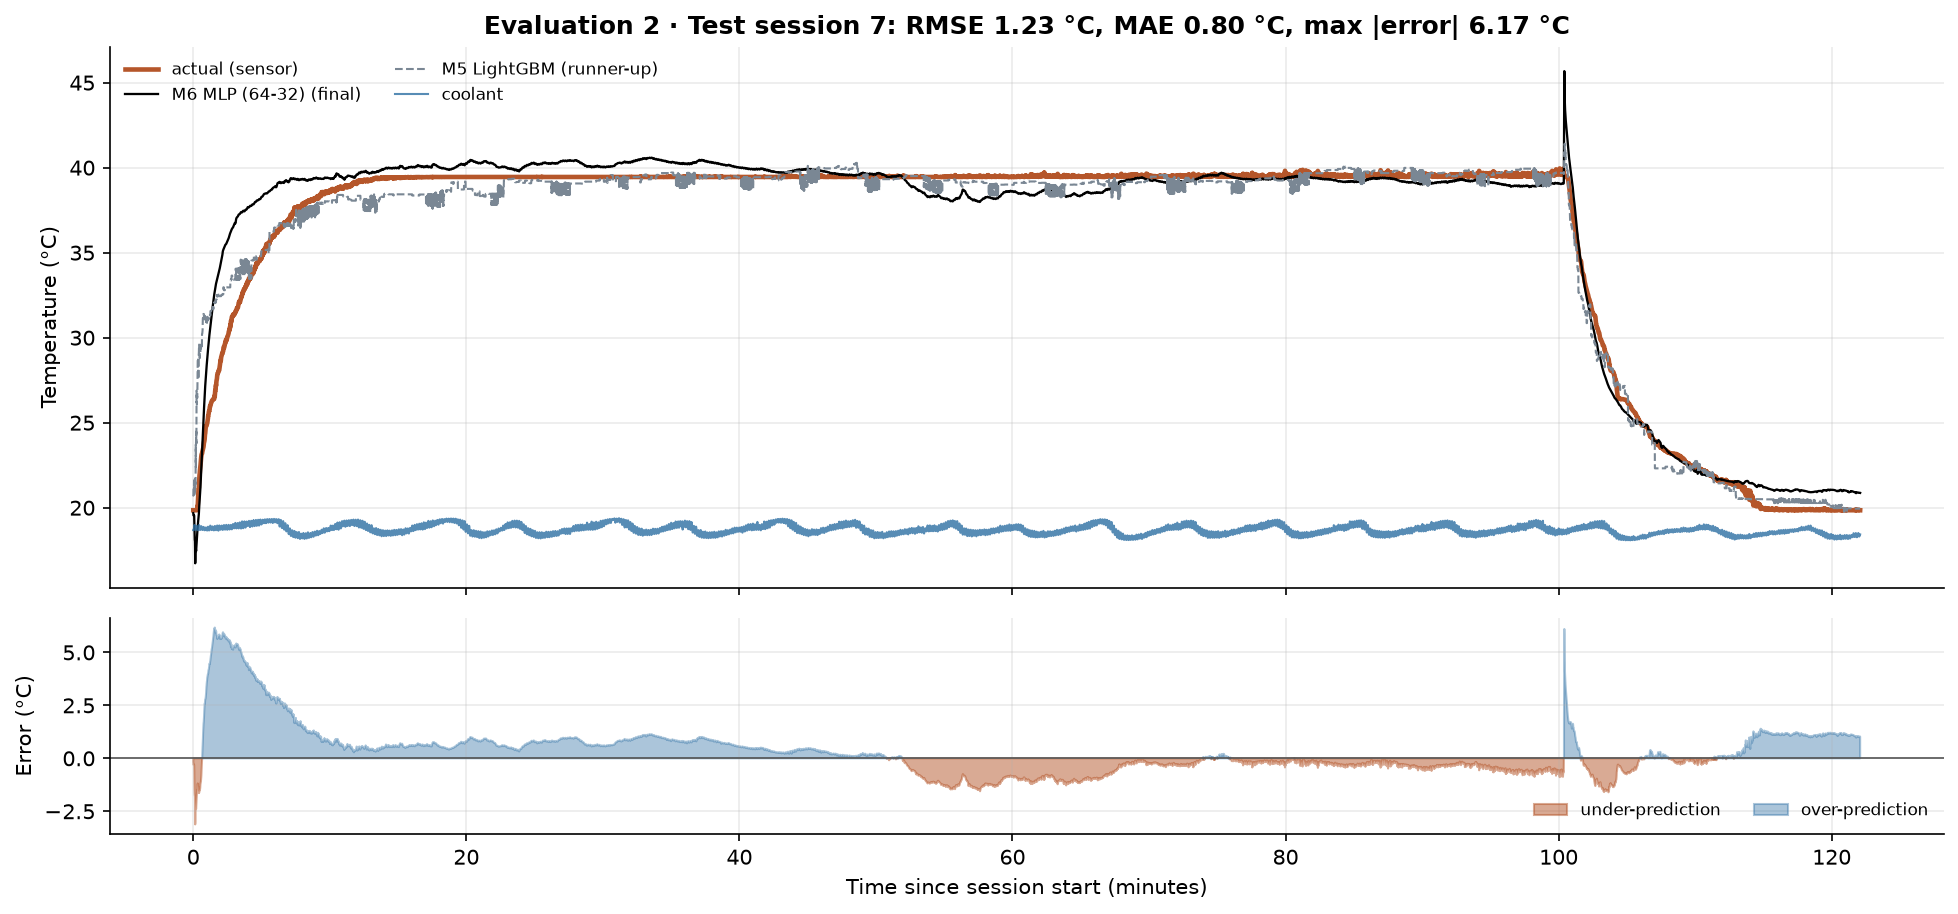

In [6]:
overall = pd.DataFrame(evaluation["overall"]).set_index("model")
display(overall[["rmse", "mae", "r2", "max_abs_error", "p95_abs_error", "mean_signed_error", "session_mean_mae"]].round(3))
display(Markdown(f"Test set opened at **{evaluation['test_opened_at']}**. Final model **{evaluation['final_model']}**. "
                 f"Targets met: target 1 **{evaluation['targets']['target_1_met']}**, target 2 **{evaluation['targets']['target_2_met']}**."))
per = pd.read_csv(R / "test_metrics_per_profile.csv")
display(per[per["model"] == evaluation["final_model"]][["profile_id", "hours", "rmse", "mae", "max_abs_error", "mean_signed_error"]].round(3))
for k, p in enumerate(split["test_profiles"][:2], start=1):
    display(Image(filename=str(F / f"eval_{k:02d}_test_session_{p}.png"), width=900))

## 7. End-to-end check: raw data → features → saved model → prediction
This cell rebuilds the features of one test session **from the raw parquet** with `src/features.py`, loads the saved final model and predicts. Its RMSE must match the Phase 5 number for that session, which proves the saved pipeline is complete and reproducible.

In [7]:
pid = split["test_profiles"][0]
info = load("model_metadata.json")["finalists"][0]
model_file = config.PROJECT_DIR / info["file"]
if model_file.exists() and config.PARQUET.exists():
    raw = pd.read_parquet(config.PARQUET, filters=[(config.GROUP, "==", pid)])
    X = features.build_features(raw)
    pred = joblib.load(model_file).predict(X[load("model_metadata.json")["features"]])
    rmse_now = regression_metrics(X[config.TARGET], pred)["rmse"]
    rmse_saved = float(per[(per["model"] == info["model"]) & (per["profile_id"] == pid)]["rmse"].iloc[0])
    print(f"Session {pid}: RMSE now {rmse_now:.4f} °C | saved in Phase 5 {rmse_saved:.4f} °C")
else:
    print("Model or data not found: run notebooks 01, 03 and 04 first (they are git-ignored).")

Session 6: RMSE now 9.4301 °C | saved in Phase 5 9.4301 °C


## 8. Innovation (Phase 6)

,variant,n_features,cv_rmse,cv_rmse_std,change_vs_full
0,full,45,4.919,0.763,0.000
1,no EWMA,13,13.176,1.367,8.257
2,no engineered,24,6.561,0.617,1.642
3,no torque,39,4.809,1.033,-0.110
4,raw only,8,13.408,1.378,8.488
5,with leakage (forbidden),48,1.146,0.112,-3.774


,memory,n_features,cv_rmse,cv_rmse_std
0,no memory,13,13.176,1.367
1,1 min,21,9.171,0.951
2,1 min + 5 min,29,5.158,0.666
3,1 min + 5 min + 15 min,37,4.996,1.180
4,1 min + 5 min + 15 min + 45 min,45,4.919,0.763


,k,margin_c,hot_rows,caught_pct,missed_hot_minutes,false_alarm_pct,false_alarm_minutes,precision_pct
0,0,0.00,14496,57.20,51.70,0.70,7.38,90.36
1,1,4.96,14496,66.43,40.55,2.30,24.28,76.78
2,2,9.92,14496,70.04,36.19,5.84,61.62,57.86


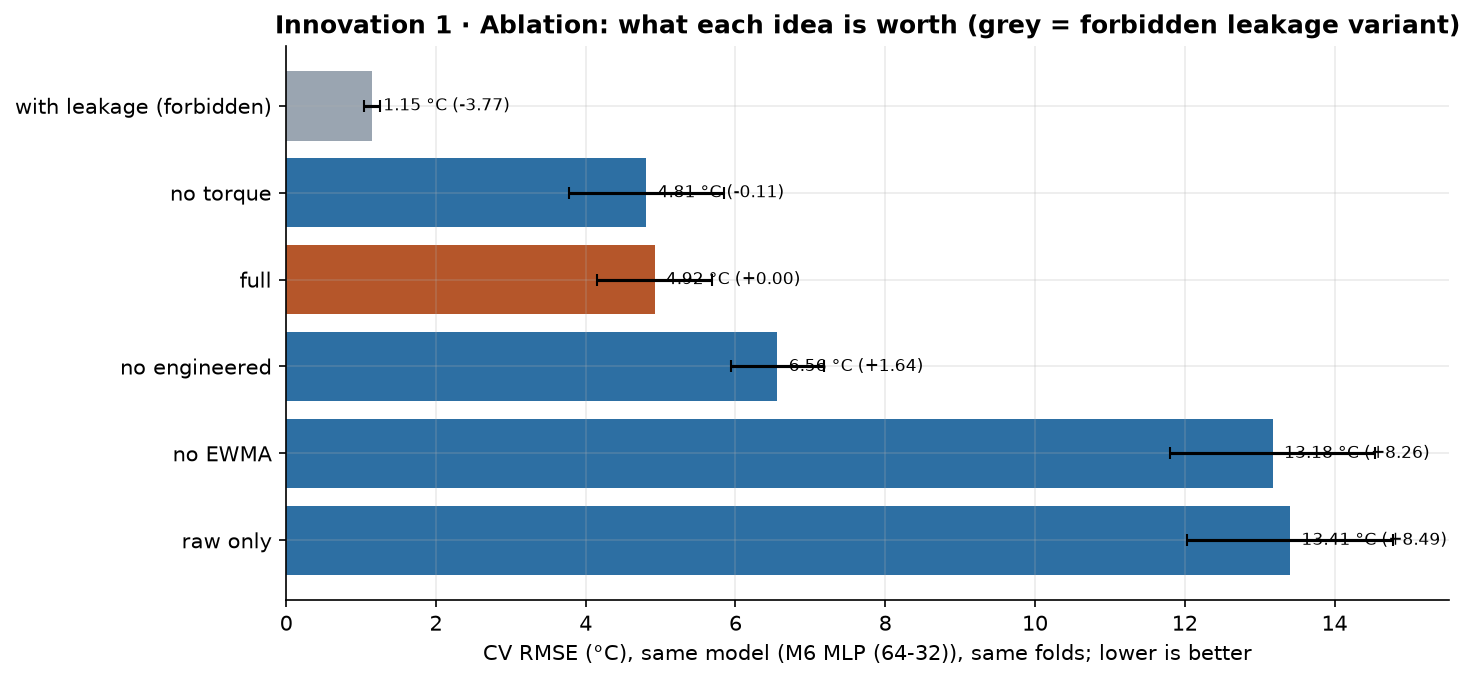

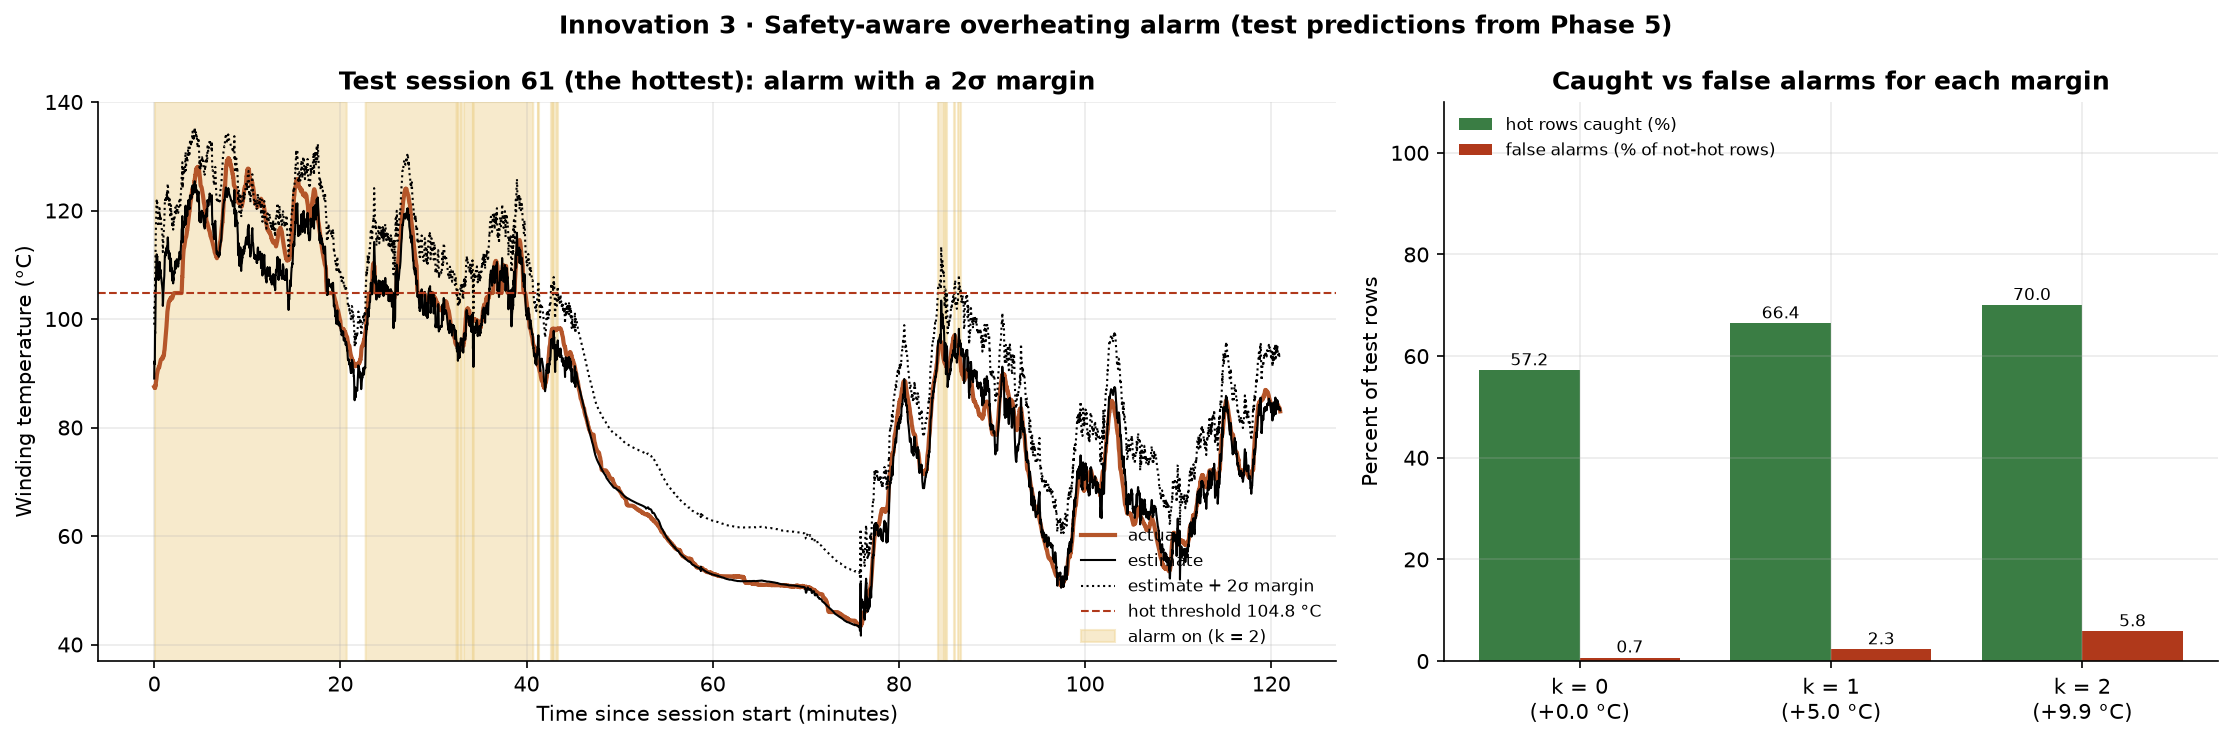

**Demo:** `streamlit run app.py` replays a test session with the live model and an overheating alarm lamp.

In [8]:
display(pd.DataFrame(innovation["ablation"])[["variant", "n_features", "cv_rmse", "cv_rmse_std", "change_vs_full"]].round(3))
display(pd.DataFrame(innovation["memory_curve"])[["memory", "n_features", "cv_rmse", "cv_rmse_std"]].round(3))
display(pd.DataFrame(innovation["safety"]["table"]).round(2))
display(Image(filename=str(F / "innov_01_ablation.png"), width=850))
display(Image(filename=str(F / "innov_03_safety_alarm.png"), width=1000))
display(Markdown("**Demo:** `streamlit run app.py` replays a test session with the live model and an overheating alarm lamp."))

## 9. Limitations and future work
- **One test-bench motor:** a different motor or a real vehicle needs new data and validation.
- **Data only up to 141.36 °C:** no promise above that.
- **Session starts (EWMA warm-up)** are harder.
- **Recorded replay, not live hardware.**
- **Future work:** compare with a first-order physics thermal model; EWMS features; a no-torque deployment model; uncertainty estimates.